# Attitude dynamics and pointing control

Every notebook so far treats the deputy as a point mass: its position and velocity matter, but never which way it is facing. A real rendezvous and proximity operation cares about that too, keeping a sensor, antenna, or docking port pointed where it needs to be while the translational dynamics built in the rest of this project fly the trajectory. This notebook builds the rotational counterpart to that point-mass dynamics: rigid body attitude kinematics and dynamics, validated the same way as everywhere else in this project, by checking the conserved quantities a torque-free case must respect, and then a simple feedback controller that points the body at a fixed target attitude.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.dynamics.attitude.rigid_body import (
    rigid_body_attitude_dynamics_symbolic, pd_pointing_attitude_dynamics_symbolic,
)
from ios_mission_planner.propagation.heyoka_propagator import propagate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## Quaternion kinematics and Euler's equations

`rigid_body_attitude_dynamics_symbolic` couples quaternion kinematics ($\dot q = \tfrac12 q \otimes \omega$) to Euler's rotational equations for a rigid body on its principal axes, with an externally supplied body-frame torque. Setting that torque to zero gives torque-free motion, which is the easiest case to validate: with no torque, both the rotational kinetic energy and the magnitude of the angular momentum vector are conserved exactly, even while the body tumbles and its orientation keeps changing.

max quaternion norm error: 2.22e-16
max kinetic energy drift: 6.66e-16
max |H| drift: 4.44e-16


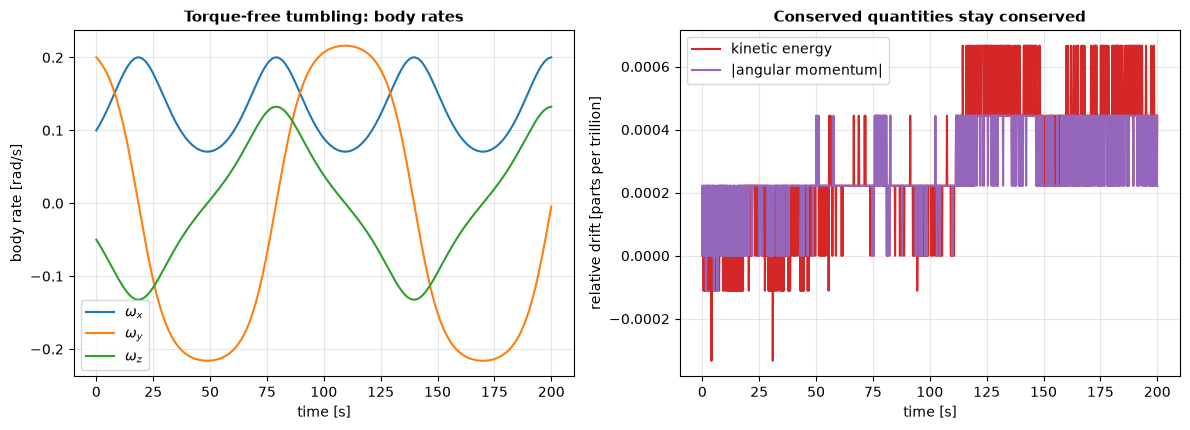

In [2]:
ix, iy, iz = 10.0, 15.0, 20.0  # kg m^2, principal moments of inertia
state0 = np.array([1.0, 0.0, 0.0, 0.0, 0.1, 0.2, -0.05])  # identity attitude, tumbling
pars_free = [ix, iy, iz, 0.0, 0.0, 0.0]

t_eval = np.linspace(0.0, 200.0, 1500)
sol = propagate(rigid_body_attitude_dynamics_symbolic(), state0, t_eval, pars=pars_free).y

q = sol[:4, :]
w = sol[4:7, :]
inertia = np.diag([ix, iy, iz])
kinetic_energy = np.array([0.5 * w[:, i] @ inertia @ w[:, i] for i in range(w.shape[1])])
h_mag = np.array([np.linalg.norm(inertia @ w[:, i]) for i in range(w.shape[1])])
q_norm = np.linalg.norm(q, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(t_eval, w[0, :], label="$\\omega_x$")
axes[0].plot(t_eval, w[1, :], label="$\\omega_y$")
axes[0].plot(t_eval, w[2, :], label="$\\omega_z$")
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("body rate [rad/s]")
axes[0].set_title("Torque-free tumbling: body rates")
axes[0].legend()

axes[1].plot(t_eval, (kinetic_energy / kinetic_energy[0] - 1) * 1e12, color=COL_NUM, label="kinetic energy")
axes[1].plot(t_eval, (h_mag / h_mag[0] - 1) * 1e12, color=COL_ZONE, label="|angular momentum|")
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("relative drift [parts per trillion]")
axes[1].set_title("Conserved quantities stay conserved")
axes[1].legend()

fig.tight_layout()

print(f"max quaternion norm error: {np.abs(1 - q_norm).max():.2e}")
print(f"max kinetic energy drift: {np.abs(kinetic_energy / kinetic_energy[0] - 1).max():.2e}")
print(f"max |H| drift: {np.abs(h_mag / h_mag[0] - 1).max():.2e}")

Both invariants stay flat to within machine precision over the whole 200-second tumble, the rotational equivalent of the two-body energy and angular momentum checks from `orbital_foundations.ipynb`, and for the same reason: nothing in the equations removes energy or momentum, so a correct integration should not either. The body rates themselves, meanwhile, visibly do not stay constant: this is a genuinely tumbling body, not a simple spin, since the inertia is different about all three axes ($I_x \ne I_y \ne I_z$).

## Pointing control

`pd_pointing_attitude_dynamics_symbolic` adds a feedback torque built from the attitude error quaternion between the current attitude and a fixed target, plus a damping term on the body rate, exactly the proportional-derivative (PD) structure used everywhere else `kp`/`kd`-style control shows up. The scenario below starts the body 60 degrees off the target attitude, at rest, and lets the controller bring it in, the kind of maneuver a real spacecraft would run to re-point a docking port or a sensor at the chief before a final approach.

pointing error: 60.0 deg -> 0.004 deg over 60 s


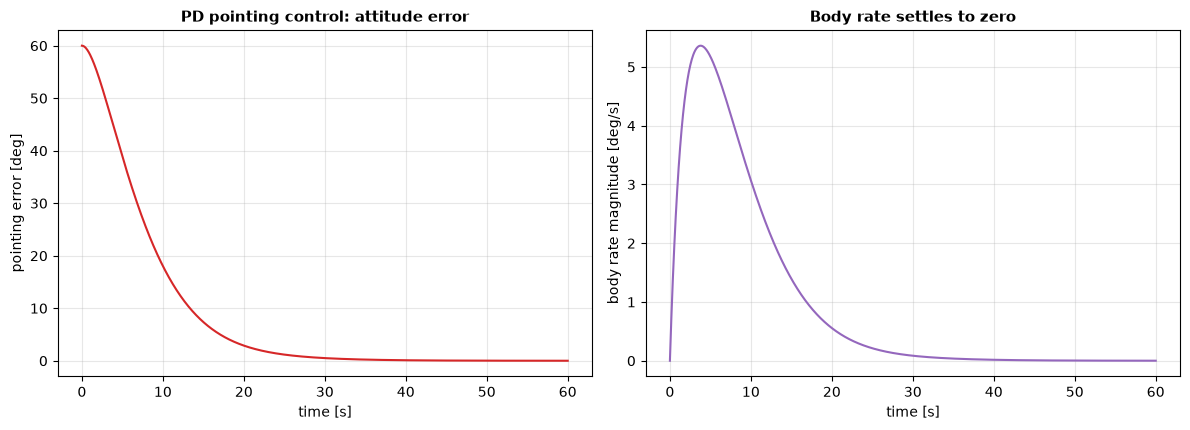

In [3]:
axis = np.array([1.0, 1.0, 1.0]) / np.sqrt(3.0)
angle0 = np.deg2rad(60.0)
q_init = np.concatenate([[np.cos(angle0 / 2)], np.sin(angle0 / 2) * axis])
state0_pd = np.concatenate([q_init, [0.0, 0.0, 0.0]])

q_target = np.array([1.0, 0.0, 0.0, 0.0])
kp, kd = 2.0, 8.0
pars_pd = [ix, iy, iz, *q_target, kp, kd]

t_eval_pd = np.linspace(0.0, 60.0, 1000)
sol_pd = propagate(pd_pointing_attitude_dynamics_symbolic(), state0_pd, t_eval_pd, pars=pars_pd).y

pointing_error_deg = 2 * np.degrees(np.arccos(np.clip(np.abs(sol_pd[0, :]), 0.0, 1.0)))
rate_mag_deg = np.degrees(np.linalg.norm(sol_pd[4:7, :], axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(t_eval_pd, pointing_error_deg, color=COL_NUM)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("pointing error [deg]")
axes[0].set_title("PD pointing control: attitude error")

axes[1].plot(t_eval_pd, rate_mag_deg, color=COL_ZONE)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("body rate magnitude [deg/s]")
axes[1].set_title("Body rate settles to zero")

fig.tight_layout()

print(f"pointing error: {pointing_error_deg[0]:.1f} deg -> {pointing_error_deg[-1]:.3f} deg over "
      f"{t_eval_pd[-1]:.0f} s")

The error settles smoothly to a small fraction of a degree, with the body rate decaying alongside it rather than oscillating, which is what a reasonably damped gain choice should look like. The quaternion norm stays at 1 throughout this run as well, the same invariant checked in the torque-free case above, confirming the control torque itself is not doing anything to break the kinematics.

## Summary

`rigid_body_attitude_dynamics_symbolic` and `pd_pointing_attitude_dynamics_symbolic` bring rotational motion into this project alongside the translational dynamics everything else is built on: quaternion kinematics coupled to Euler's equations, validated against the same kind of conservation checks used for the two-body problem, plus a PD controller that demonstrably drives a 60-degree pointing error down to a small fraction of a degree with a well-damped response.

This notebook stays deliberately self-contained. The attitude state here is not yet coupled to the orbital or relative-motion state, the torque is ideal, with no actuator behind it, and the controller assumes the attitude and rate are known exactly rather than measured. The next two notebooks remove the last assumption, first with single-instant attitude determination and then with a recursive filter. `attitude_coupled_pointing.ipynb` then ties the pointing target to a real relative trajectory, and the closed-loop docking simulation puts reaction wheels with real limits behind the torque.